<a href="https://colab.research.google.com/github/LamyaDev/My-projects/blob/main/Restaurant%D9%80Data%D9%80Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

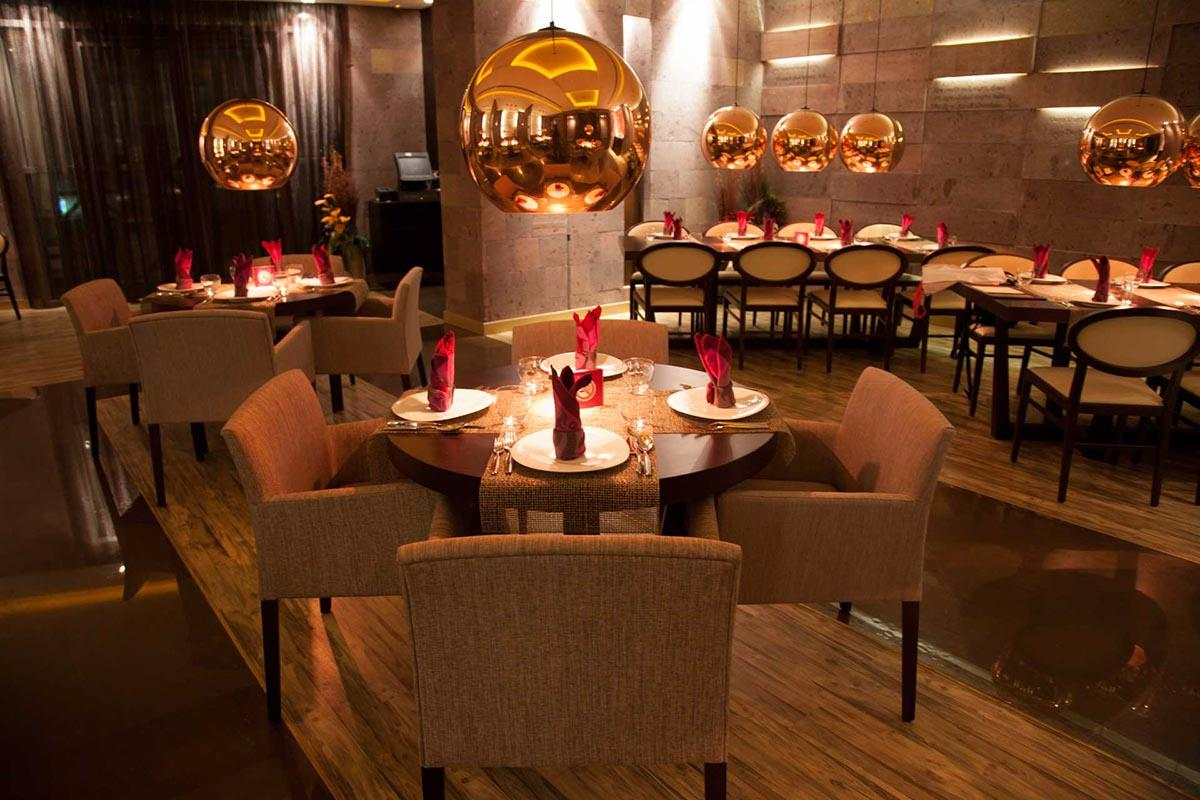

# Restaurant Data Analysis


This project analyzes a restaurant dataset containing 9,551 records and 21 columns. The analysis explores restaurant locations, cuisines, prices, customer ratings, and online delivery. The goal is to identify market trends, understand customer preferences, and help business owners make better decisions about pricing, services, and potential business opportunities.


Import libraries and load the dataset

In [ ]:
import pandas as pd

In [ ]:
df = pd.read_csv('Zomato Restaurant Dataset.csv')

In [ ]:
df.head()

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


Understand the dataset

In [ ]:
df.shape

(9551, 21)

In [ ]:
df.index

RangeIndex(start=0, stop=9551, step=1)

In [ ]:
df.columns

Index(['Restaurant ID', 'Restaurant Name', 'Country Code', 'City', 'Address',
       'Locality', 'Locality Verbose', 'Longitude', 'Latitude', 'Cuisines',
       'Average Cost for two', 'Currency', 'Has Table booking',
       'Has Online delivery', 'Is delivering now', 'Switch to order menu',
       'Price range', 'Aggregate rating', 'Rating color', 'Rating text',
       'Votes'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9551 entries, 0 to 9550
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Restaurant ID         9551 non-null   int64  
 1   Restaurant Name       9551 non-null   object 
 2   Country Code          9551 non-null   int64  
 3   City                  9551 non-null   object 
 4   Address               9551 non-null   object 
 5   Locality              9551 non-null   object 
 6   Locality Verbose      9551 non-null   object 
 7   Longitude             9551 non-null   float64
 8   Latitude              9551 non-null   float64
 9   Cuisines              9542 non-null   object 
 10  Average Cost for two  9551 non-null   int64  
 11  Currency              9551 non-null   object 
 12  Has Table booking     9551 non-null   object 
 13  Has Online delivery   9551 non-null   object 
 14  Is delivering now     9551 non-null   object 
 15  Switch to order menu 

In [ ]:
df.count()

,0
Restaurant ID,9551
Restaurant Name,9551
Country Code,9551
City,9551
Address,9551
Locality,9551
Locality Verbose,9551
Longitude,9551
Latitude,9551
Cuisines,9542


 Check data quality and missing values

In [ ]:
df.isnull().sum()

,0
Restaurant ID,0
Restaurant Name,0
Country Code,0
City,0
Address,0
Locality,0
Locality Verbose,0
Longitude,0
Latitude,0
Cuisines,3


In [ ]:
missing_cuisines = df[df['Cuisines'].isnull()]

for index, row in missing_cuisines.iterrows():
    print(f"\n--- Index: {index} ---")
    print(row)



--- Index: 84 ---
Restaurant ID                                     17284105
Restaurant Name                              Cookie Shoppe
Country Code                                           216
City                                                Albany
Address                 115 N Jackson St, Albany, GA 31701
Locality                                            Albany
Locality Verbose                            Albany, Albany
Longitude                                          -84.154
Latitude                                           31.5772
Cuisines                                               NaN
Average Cost for two                                     0
Currency                                         Dollar($)
Has Table booking                                       No
Has Online delivery                                     No
Is delivering now                                       No
Switch to order menu                                    No
Price range                          

# Fill missing Cuisines values

In [ ]:

cuisine_updates = {
    84: "American",
    94: "Hot Dogs, Sandwiches",
    328: "American, Southern, Farm-to-table",
    368: "American",
    418: "Bakery, Portuguese",
    455: "Caribbean, Latin American, Seafood"
}

for index, cuisine in cuisine_updates.items():
    if pd.isna(df.loc[index, "Cuisines"]):
        df.loc[index, "Cuisines"] = cuisine



# Display updated restaurants

In [ ]:
df.loc[
    [84, 87, 94, 297, 328, 346, 368, 418, 455],
    ["Restaurant Name", "Cuisines"]
]

,Restaurant Name,Cuisines
84,Cookie Shoppe,American
87,Pearly's Famous Country Cookng,NaN
94,Jimmie's Hot Dogs,"Hot Dogs, Sandwiches"
297,Corkscrew Cafe,NaN
328,Dovetail,"American, Southern, Farm-to-table"
346,HI Lite Bar & Lounge,NaN
368,Hillstone,American
418,Leonard's Bakery,"Bakery, Portuguese"
455,Tybee Island Social Club,"Caribbean, Latin American, Seafood"


In [ ]:
df[df["Cuisines"].isna()]

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
87,17284211,Pearly's Famous Country Cookng,216,Albany,"814 N Slappey Blvd, Albany, GA 31701",Albany,"Albany, Albany",-84.1759,31.5882,NaN,...,Dollar($),No,No,No,No,1,3.4,Orange,Average,36
297,17374552,Corkscrew Cafe,216,Gainesville,"51 W Main St, Dahlonega, GA 30533",Dahlonega,"Dahlonega, Gainesville",-83.9858,34.5318,NaN,...,Dollar($),No,No,No,No,3,3.9,Yellow,Good,209
346,17606621,HI Lite Bar & Lounge,216,Miller,"109 N Broadway Ave, Miller, SD 57362",Miller,"Miller, Miller",-98.9891,44.5158,NaN,...,Dollar($),No,No,No,No,1,3.4,Orange,Average,11


# Count restaurants in each city

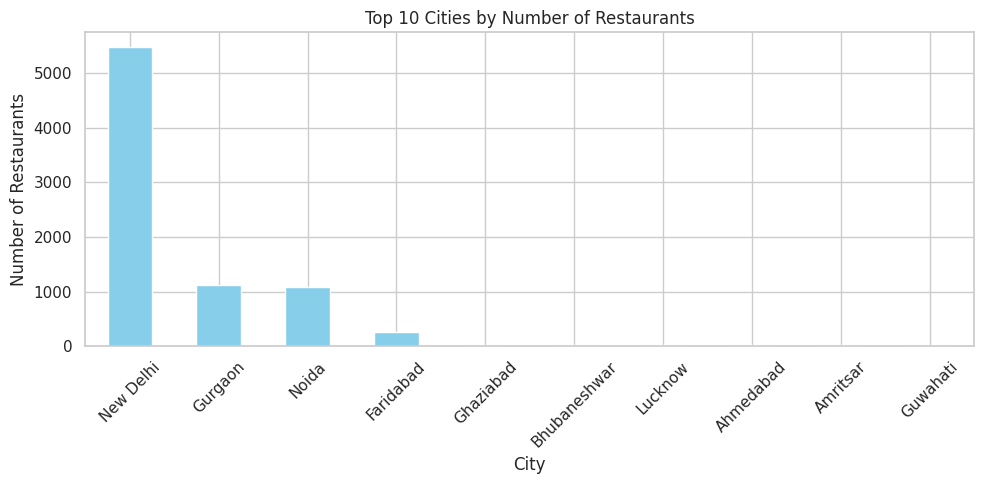

In [ ]:
import matplotlib.pyplot as plt

city_counts = df["City"].value_counts().head(10)

plt.figure(figsize=(10, 5))
city_counts.plot(kind="bar", color="skyblue")

plt.title("Top 10 Cities by Number of Restaurants")
plt.xlabel("City")
plt.ylabel("Number of Restaurants")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Conclusion: New Delhi has the highest number of restaurants (5,473), followed by Gurgaon (1,118) and Noida (1,080).

What we learned: Restaurants in this dataset are heavily concentrated in New Delhi. This helps identify the largest restaurant markets and where business competition may be strongest.

# Which restaurants have the highest ratings?

<Axes: xlabel='Restaurant Name'>

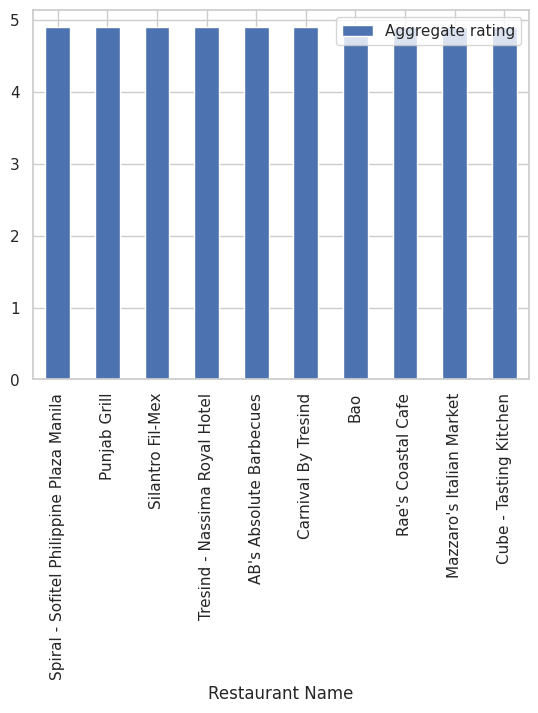

In [ ]:
import matplotlib.pyplot as plt

top_restaurants.plot(
    x="Restaurant Name",
    y="Aggregate rating",
    kind="bar"
)



Conclusion: The top 10 restaurants all have a rating of 4.9 out of 5, with votes ranging from 107 to 1,424.

What we learned: These restaurants have excellent customer ratings and a reasonable number of votes, making them strong examples of highly rated restaurants in the dataset.

#Do more expensive restaurants have higher ratings?

In [ ]:
# Average rating for each price range

price_ratings = df.groupby("Price range")["Aggregate rating"].mean()

display(price_ratings)

,Aggregate rating
Price range,
1,1.999887
2,2.941054
3,3.683381
4,3.817918


Conclusion: Higher-priced restaurants tend to have higher average ratings. Price range 4 has the highest average rating (3.82), while price range 1 has the lowest (2.00).

What we learned: More expensive restaurants generally receive better ratings in this dataset, but this does not prove that higher prices cause greater customer satisfaction

#What are the most common cuisines?

In [ ]:
# Top 10 most common cuisines

top_cuisines = df["Cuisines"].dropna().str.split(", ").explode().value_counts().head(10)

display(top_cuisines)

,count
Cuisines,
North Indian,3960
Chinese,2735
Fast Food,1986
Mughlai,995
Italian,764
Bakery,746
Continental,736
Cafe,703
Desserts,653


Conclusion: North Indian is the most common cuisine (3,960 occurrences), followed by Chinese (2,735) and Fast Food (1,986).

What we learned: North Indian cuisine dominates the dataset, suggesting strong representation of Indian food preferences.




#Is the number of votes related to restaurant ratings?

In [ ]:

# Correlation between votes and ratings

correlation = df["Votes"].corr(df["Aggregate rating"])

print("Correlation:", correlation)


Correlation: 0.31369058419541157


Conclusion: The correlation is approximately 0.31, indicating a weak positive relationship between the number of votes and restaurant ratings.

What we learned: Restaurants with more votes tend to have slightly higher ratings, but the relationship is not strong.

#Does online delivery affect restaurant ratings?

In [ ]:

# Average rating by online delivery availability

delivery_ratings = df.groupby("Has Online delivery")["Aggregate rating"].mean()

display(delivery_ratings)

,Aggregate rating
Has Online delivery,
No,2.465296
Yes,3.248837


Conclusion: Restaurants offering online delivery have a higher average rating (3.25) than those without delivery (2.47).

What we learned: Online delivery availability is associated with higher restaurant ratings in this dataset, but this does not prove that delivery causes better rating

# Which price range is the most common

In [ ]:
df["Price range"].value_counts().sort_index()

,count
Price range,
1,4444
2,3113
3,1408
4,586


# Conclusion:
Price range 1 is the most common, with 4,444 restaurants, followed by price range 2 (3,113). Price range 4 is the least common, with 586 restaurants.

# What we learned:
 Most restaurants in the dataset belong to the lower price ranges, suggesting that affordable dining options dominate the dataset.

# Overall Conclusion

The analysis of the Zomato dataset helped us understand restaurant distribution across cities, customer ratings, pricing, popular cuisines, and online delivery services. We found that New Delhi has the highest number of restaurants, higher-priced restaurants tend to receive better ratings, and restaurants offering online delivery have higher average ratings. We also identified the most popular cuisines and price ranges.



---


# Business Value:
 These insights help restaurant owners identify target markets, understand customer preferences, set competitive prices, improve service offerings, and evaluate business opportunities. Overall, data analysis supports better, evidence-based decisions and helps businesses understand market trends and customer satisfaction.


